# 4. TOP Users and Insurance Analysis
## Purpose: Opportunity Analysis of Top User States Vs Top Insurance Penetration

C:\Users\Vijay\AppData\Local\Temp\ipykernel_21024\1937662986.py:40: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


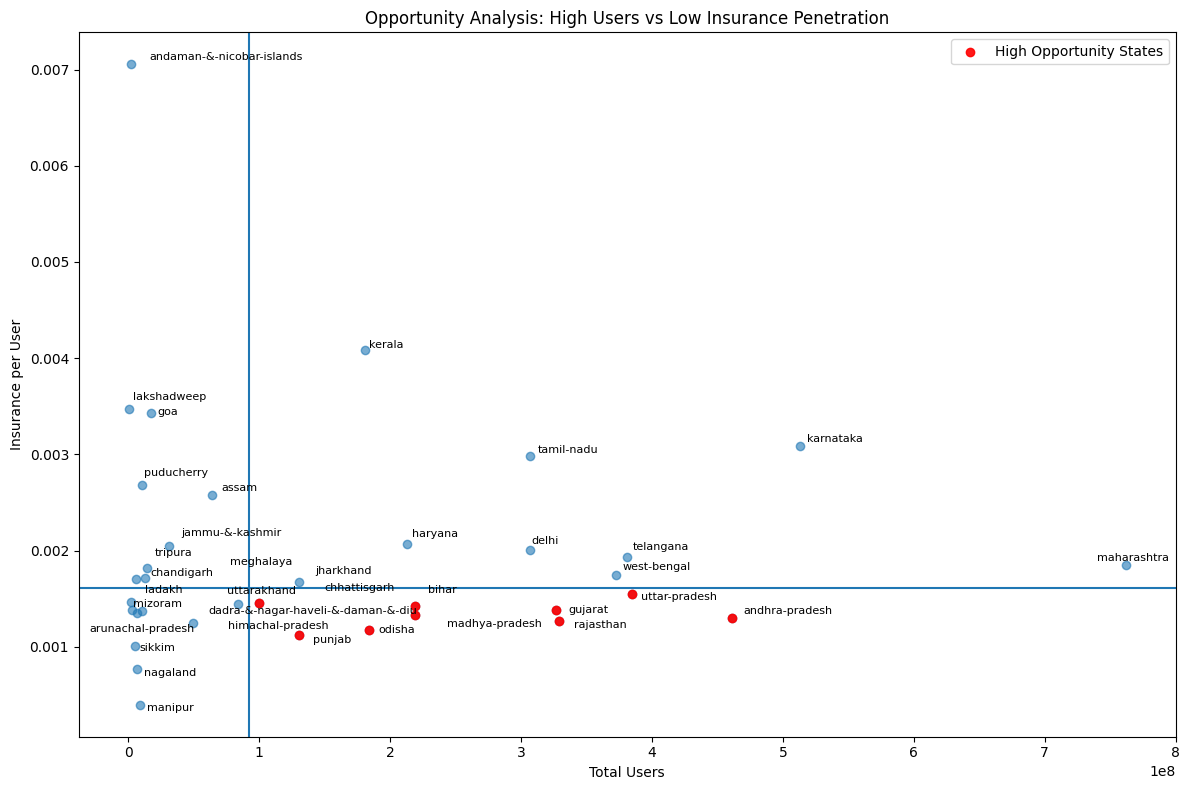

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import mysql.connector
from adjustText import adjust_text

# ------------------ DB CONNECTION ------------------
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="12345678",
    database="phonepe_db"
)

# ------------------ QUERY (ONLY USER + INSURANCE) ------------------
query = """
WITH user_data AS (
    SELECT 
        State,
        SUM(Registered_users) AS Total_Users
    FROM top_user
    GROUP BY State
),

insurance_data AS (
    SELECT 
        State,
        SUM(Transaction_count) AS Total_Insurance_Count
    FROM top_insurance
    GROUP BY State
)

SELECT 
    u.State,
    u.Total_Users,
    i.Total_Insurance_Count
FROM user_data u
JOIN insurance_data i ON u.State = i.State;
"""

df = pd.read_sql(query, conn)

# ------------------ DERIVED METRIC ------------------
df["Insurance_per_User"] = df["Total_Insurance_Count"] / df["Total_Users"]

# ------------------ MEDIANS ------------------
x_median = df["Total_Users"].median()
y_median = df["Insurance_per_User"].median()

# ------------------ PLOT ------------------
plt.figure(figsize=(12, 8))

# Base scatter
plt.scatter(
    df["Total_Users"],
    df["Insurance_per_User"],
    alpha=0.6
)

# ------------------ HIGHLIGHT OPPORTUNITY ------------------
opportunity = df[
    (df["Total_Users"] > x_median) &
    (df["Insurance_per_User"] < y_median)
]

plt.scatter(
    opportunity["Total_Users"],
    opportunity["Insurance_per_User"],
    color='red',
    alpha=0.9,
    label="High Opportunity States"
)

# ------------------ LABELS (AUTO ADJUSTED) ------------------
texts = []
for i in range(len(df)):
    texts.append(
        plt.text(
            df["Total_Users"].iloc[i],
            df["Insurance_per_User"].iloc[i],
            df["State"].iloc[i],
            fontsize=8
        )
    )

adjust_text(texts)

# ------------------ QUADRANT LINES ------------------
plt.axvline(x_median)
plt.axhline(y_median)

# ------------------ TITLES ------------------
plt.title("Opportunity Analysis: High Users vs Low Insurance Penetration")
plt.xlabel("Total Users")
plt.ylabel("Insurance per User")

plt.legend()

plt.tight_layout()
plt.show()